In [4]:
# load in packages needed for the assignment 
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random 

# Linear model and basic functions from scikit-learn
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Specific models we will use beyond linear regression from scikit-learn
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import RadiusNeighborsRegressor
from sklearn.linear_model import LinearRegression

In [5]:
# load in the csv file with surface water data  

# set the path to the correct directory for your particular computer
infile = r'C:\Users\joann\OEAS805\HW3\CBP_TWQM_MAIN_WQ_2021_2026_surface.csv'

# read in the .csv file with the column separator explicitly defined
data = pd.read_csv(infile, sep = ',' , low_memory = False)

In [6]:
# print the information about the data in the dataframe
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1223 entries, 0 to 1222
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Station                1223 non-null   str    
 1   FieldActivityId        1223 non-null   int64  
 2   Cruise                 1223 non-null   str    
 3   Program                1223 non-null   str    
 4   Project                1223 non-null   str    
 5   DataCollector          1223 non-null   str    
 6   DataProvider           1223 non-null   str    
 7   Latitude               1223 non-null   float64
 8   Longitude              1223 non-null   float64
 9   SampleDate             1223 non-null   str    
 10  SampleTime             1223 non-null   str    
 11  TotalDepthM            1223 non-null   float64
 12  UpperPycnoclineDepthM  1022 non-null   float64
 13  LowerPycnoclineDepthM  1022 non-null   float64
 14  SampleDepthM           1223 non-null   float64
 15  Layer          

In [8]:
# the shape of the data
# nrows, ncols
data.shape

(1223, 29)

The dataset is in "long format" where all the water quality parameters are stored in a single column called "Parameter" and their corresponding measurements are in "MeasureValue". I will run a code to covert the data into "wide format" using pandas.

In [17]:
# pivot dataset so each parameter becomes its own column
data_wide = data.pivot_table(
    index=['SampleDate', 'SampleTime', 'TotalDepthM'], 
    columns='Parameter', 
    values='MeasureValue'
).reset_index()

# check the new column names
print(data_wide.columns.tolist())

['SampleDate', 'SampleTime', 'TotalDepthM', 'CHLA', 'DIN', 'DO', 'DON', 'DOP', 'KD', 'NH4F', 'NO23F', 'NO2F', 'NO3F', 'PC', 'PH', 'PHEO', 'PN', 'PO4F', 'PP', 'SALINITY', 'SECCHI', 'SIGMA_T', 'SPCOND', 'TDN', 'TDP', 'TN', 'TON', 'TP', 'TSS', 'WTEMP']


The water quality parameters are now listed above. I will determine if any of these parameters contain NaN values before selecting my target parameter.

In [15]:
# check missing values across all parameter columns
(data_wide.isna().sum())

Parameter
SampleDate     0
SampleTime     0
TotalDepthM    0
CHLA           0
DIN            0
DO             0
DON            0
DOP            0
KD             0
NH4F           0
NO23F          0
NO2F           0
NO3F           0
PC             0
PH             0
PHEO           0
PN             0
PO4F           0
PP             0
SALINITY       0
SECCHI         0
SIGMA_T        0
SPCOND         0
TDN            0
TDP            0
TN             0
TON            0
TP             0
TSS            0
WTEMP          0
dtype: int64

None of the parameters contain missing values. I will choose CHLA (chorophyll a) as my target variable. My input (predictor) variables will include nutrients (TN, TP, DIN, PO4F), water clarity (SECCHI), temperature, salinity, and pH. I chose these as my predictor variables because algae require nutrients and sunlight (water clarity measured via secchi disk) to grow. Temperature and salinity also regulate seasonal growth cycles, and photosynthesizing algae alter water pH. 

In [19]:
# define target (y) and predictor variables (X)
target_col = 'CHLA'
feature_cols = ['TN', 'TP', 'DIN', 'PO4F', 'SECCHI', 'WTEMP', 'SALINITY', 'PH']

# extract x and y from data_wide 
X = data_wide[feature_cols]
y = data_wide[target_col]

# check shapes to make sure everything matches
print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

Features shape (X): (42, 8)
Target shape (y): (42,)


In [21]:
# split the water quality data into training/testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)

In [22]:
# model 1: linear regression 
regr_lr = LinearRegression()
regr_lr.fit(X_train, y_train)
y_pred_lr = regr_lr.predict(X_test)

print("Linear Regression R2 score: %.2f" % r2_score(y_test, y_pred_lr))

Linear Regression R2 score: 0.66


This model explains 66% of the variance in Chlorophyll a using nutrient, temperature, salinity, and pH inputs. 

In [38]:
# model 2: K-Nearest Neighbors (KNN) Regressor 

k = int(input('Choose a number for k: '))

regr_knn = KNeighborsRegressor(n_neighbors=k)
regr_knn.fit(X_train, y_train)
y_pred_knn = regr_knn.predict(X_test)

print("KNN Regressor R2 score: %.2f" % r2_score(y_test, y_pred_knn))

Choose a number for k:  33


KNN Regressor R2 score: -0.04


Any value greater than 33 breaks the model. An input of 1 resulted in a lower negative R2 value, and increasing the input increased the R2 closer to 0. This is true except for inputs of k=30 (R2=0.02) and k=31 (R2=0.03). Setting k to 33 forces KNN to average all the training points (42 samples x 0.8 for training = 33 samples), which defaults to the dataset mean. Inputting k values close to the number of training points makes the model perform slightly better than predicting the average Chl a value for every sample, but the R2 value is still too low to be meaningful. This model likely failed because KNN calculates physical distances between variables, so predictors with larger values like temperature dominate predictors with small decimal values like nutrients. 

In [45]:
# model 3: Multi-Layer Perceptron (MLP) Regressor 

n = int(input('Choose a number for hidden nodes: '))

regr_mlp = MLPRegressor(hidden_layer_sizes=(n, n), activation='relu', max_iter=10000, random_state=4)
regr_mlp.fit(X_train, y_train)
y_pred_mlp = regr_mlp.predict(X_test)

print("MLP Regressor R2 score: %.2f" % r2_score(y_test, y_pred_mlp))

Choose a number for hidden nodes:  12


MLP Regressor R2 score: 0.66


A node count of 12 gave me the highest R2 value. Any value lower or higher than 12 underfits or overfits the data. At 12 nodes, the model captures the underlying relationships between the predictor variables and Chl A without memorizing noise. 

Mean squared error: 13.73
Coefficient of determination (R-squared): 0.66


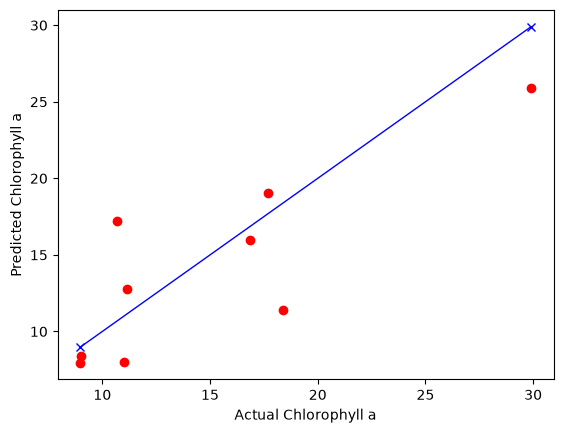

In [48]:
# Evaluate model performance:
# The mean squared error (lower numbers, better accuracy)
print('Mean squared error: %.2f'
      % mean_squared_error(y_test, y_pred_lr))
# The coefficient of determination: 1 is perfect prediction
print('Coefficient of determination (R-squared): %.2f'
      % r2_score(y_test, y_pred_lr))

# Plot outputs
# Put Actual values on X-axis, and Predicted values on Y-axis
plt.scatter(y_test, y_pred_lr, color='red')

# Draw a 1:1 line representing perfect predictions instead of y = m*x + b
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '-x', color='blue', linewidth=1)

plt.xlabel('Actual Chlorophyll a')
plt.ylabel('Predicted Chlorophyll a')
plt.show()

The RMSE (root mean sqaured error) would be 3.71 ug/L, which means the models predictions for Chl a are off by +/-3.71 ug/L. This, combined with an R2 of 0.66, shows that the combination of nutrients, temperature, salinity, and pH gives a reliable estimate of algal biomass in the bay. 

Choose a number for k:  31


R-squared score: 0.03


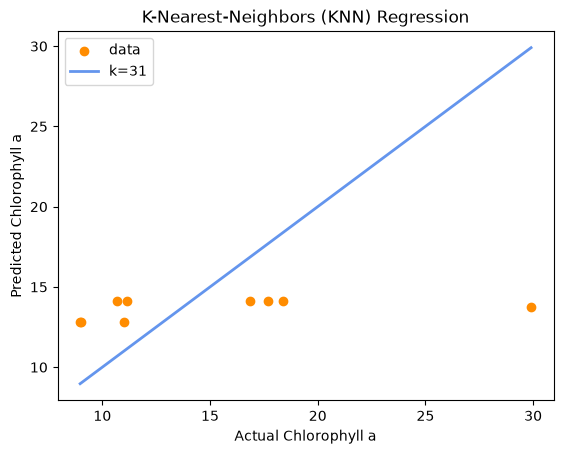

In [69]:
# choose the number of neighbors = 'k'
k = int(input('Choose a number for k: '))

# fit regression model
regr_1 = KNeighborsRegressor(n_neighbors=k)
regr_1.fit(X_train, y_train)

# predict using test set
y_1 = regr_1.predict(X_test)

# compute the R-squared score
print("R-squared score: {0:.2f}".format(regr_1.score(X_test, y_test)))

# plot the model together with the data 
plt.figure()
plt.scatter(y_test, y_1, c="darkorange", label="data")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="cornflowerblue", label="k="+str(k), linewidth=2)
plt.xlabel("Actual Chlorophyll a")
plt.ylabel("Predicted Chlorophyll a")
plt.title("K-Nearest-Neighbors (KNN) Regression")
plt.legend()
plt.show()

The plot shows extreme underfitting. Even when the input of k yields the highest R2 value, it is obvious that this model is not suited for this dataset (datapoints not even close to the 1:1 line). 

Choose a number for hidden nodes:  12


MLP Regressor R2 score: 0.66


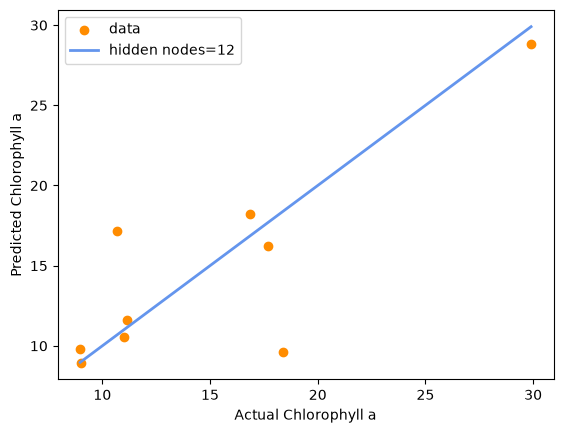

In [73]:
# choose the number of hidden nodes
n = int(input('Choose a number for hidden nodes: '))

# fit the MLP regression model
regr_mlp = MLPRegressor(hidden_layer_sizes=(n, n), activation='relu', max_iter=10000, random_state=4)
regr_mlp.fit(X_train, y_train)

# predict using the test set
y_pred_mlp = regr_mlp.predict(X_test)

# compute the R-squared score
print("MLP Regressor R2 score: %.2f" % r2_score(y_test, y_pred_mlp))

# plot the results 
plt.figure()
plt.scatter(y_test, y_pred_mlp, c="darkorange", label="data")

# 1:1 Reference line 
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="cornflowerblue", label="hidden nodes="+str(n), linewidth=2)

plt.xlabel("Actual Chlorophyll a")
plt.ylabel("Predicted Chlorophyll a")
plt.legend()
plt.show()

I created an MLP network using 2 hidden layers and 12 hidden nodes (144 total connections) to yield the highest R2 value (datapoints closest to the 1:1 line). An R2 value of 0.66 implies the model effectively learns complex relationships between water quality variables. A model containing fewer than 12 nodes for this dataset lacks the processing capacity to learn the patterns, while a model containing more than 12 nodes allows the network to memorize random noise in the training set. I chose two hidden layers instead of one due to the variability in predictors. This gives the network the framework for layer 1 to model physical conditions and layer 2 to model nutrients. 

Model summaries: 

KNN: I evaluated a range of k values from 1-33, since any k value above 33 broke the model. This analysis failed to build a functional model (R2 = 0.03), likely because I chose predictor variables with a wide range of numeric values (e.g. temp vs nutrients) or because this dataset originates from a single monitoring station. The lack of spatial variability may make it difficult for KNN to form useful neighbor groups. 

MLP: An architecture of 12 nodes per layer yielded the most functional model (R2 = 0.66), while any value less than 12 underfit and any value over 12 overfit the model. Two layers allowed the network to capture the complex interactions across all 8 parameters. 

Conclusions:

Both multiple linear regression and the MLP model performed the best and were in agreeance (R2 = 0.66), whereas KNN failed. These models show that there is a relationship between Chlorophyll a levels and the combination of nutrient availability, water clarity, temperature, salinity, and pH. The remaining ~34% of unexplained variance may be due to photoacclimation. Phytoplankton can alter their internal Chlorophyll a concentrations in response to light, meaning Chl a levels can fluctuate due to cell physiology alongside environmental parameters.